# Auxiliary-loss-free load balancing

*DeepSeek-V3 technical report, section 2.1.2 and section 4.5. Notebook 3 of 8.*

**TL;DR.** An MoE model only works if its experts are used about equally. If a few experts get most of the tokens, the GPUs holding the rest sit idle and the unused experts never learn. The standard cure is an extra loss term that pushes the router towards balance, but that term competes with the language-modelling loss. DeepSeek-V3 drops it as the main mechanism. Each expert gets a **bias** that is added to its score **only when choosing** the top-k experts. After every step, the bias of an overloaded expert goes down a little and the bias of an underloaded expert goes up a little. No gradient is involved. This notebook builds the mechanism, shows it balancing a deliberately skewed problem, measures how it compares with the loss-based approach in terms of balance *and* accuracy, and checks the claim in the paper that it lets experts specialise more.

| step | what we do |
|---|---|
| 1 | routing collapse: why balance matters, and what the classic auxiliary loss does |
| 2 | the bias mechanism, built and traced |
| 3 | the one detail that matters: the bias must not touch the gate values |
| 4 | a skewed problem: balance versus accuracy for both approaches |
| 5 | the complementary sequence-wise loss, and why it is still there |
| 6 | specialisation (paper Figure 9) |
| 7 | the same comparison in a small language model |

In [1]:
import sys, math, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))             # the notebook lives next to dsv3kit.py
import dsv3kit as K                             # tested building blocks; this notebook re-shows the code it uses

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C = dict(blue="#1f78b4", orange="#d95f02", green="#1b9e77", purple="#7570b3", red="#c0392b", grey="#777777")

PASS, FAIL = [], []
def check(name, ok, detail=""):
    (PASS if ok else FAIL).append(name)
    print(("PASS" if ok else "FAIL"), "-", name, detail)

print("torch", torch.__version__)

torch 2.14.1


## 1. Why balance matters, and the classic fix

In notebook 2 each token picks its top-$K_r$ experts by router score. Nothing in that rule makes the experts equally popular, and training makes it worse: an expert that gets more tokens trains faster, gets better, and is chosen even more. This is called **routing collapse**. Two things go wrong:

- **Efficiency.** With experts spread over GPUs, a layer finishes when its busiest expert finishes. If one expert gets 4x its fair share, most GPUs wait.
- **Capacity.** Experts nobody picks are wasted parameters.

The standard remedy (GShard, Switch Transformer) adds an **auxiliary loss** to the training objective. For each expert $i$, let $f_i$ be the fraction of tokens routed to it and $P_i$ the average router probability it gets; the loss $\alpha \sum_i f_i P_i$ is smallest when both are uniform. The notebook-2 kit already contains this loss (the paper's equations 17 to 20, applied to a whole batch or a single sequence). The trouble, as the paper notes, is that it is a **gradient pushing on the router in addition to the language-modelling gradient**: a large $\alpha$ buys balance at the price of accuracy, a small $\alpha$ lets the imbalance through.

DeepSeek-V3's idea: balance does not have to be a gradient. It can be a **control loop** on the routing decision.

## 2. The bias mechanism

Each routed expert $i$ gets a scalar bias $b_i$ (starting at zero). The router's affinity $s_{i,t}$ is unchanged, but the *selection* of the top-$K_r$ experts uses $s_{i,t} + b_i$ (paper eq. 16):

$$
g'_{i,t} = \begin{cases} s_{i,t}, & s_{i,t} + b_i \in \mathrm{Top}K_r\big(\{s_{j,t}+b_j\}\big) \\ 0 & \text{otherwise.} \end{cases}
$$

At the end of every training step we look at how many tokens each expert received **in that whole batch**, and move each bias by a fixed amount $\gamma$ (the "bias update speed"):

$$ b_i \leftarrow b_i - \gamma \quad\text{if expert } i \text{ was overloaded}, \qquad b_i \leftarrow b_i + \gamma \quad\text{if underloaded.} $$

Overloaded means more than the average load. This is what the kit's `update_bias` does:

In [2]:
from dsv3kit import DeepSeekMoE   # the layer from notebook 2; update_bias and the loss below act on it

@torch.no_grad()
def update_bias(moe: DeepSeekMoE, gamma: float):
    """Auxiliary-loss-free balancing: overloaded expert -> bias down by gamma, underloaded -> up by gamma."""
    load = moe.last["load"].float()
    moe.bias += gamma * torch.sign(load.mean() - load)


def seq_balance_loss(moe: DeepSeekMoE, B: int, T: int, alpha: float):
    """Complementary sequence-wise balance loss, eqs. (17)-(20): alpha * sum_i f_i P_i per sequence."""
    aff, idx = moe.last["aff"], moe.last["idx"]
    Nr, K = moe.n_routed, idx.shape[1]
    s_norm = aff.view(B, T, Nr) / aff.view(B, T, Nr).sum(-1, keepdim=True)            # s'_{i,t}
    P = s_norm.mean(1)                                                                # (B, Nr)
    picked = F.one_hot(idx.view(B, T, K), Nr).sum(2).float()                          # (B, T, Nr)
    f = picked.mean(1) * Nr / K                                                       # f_i = Nr/(K T) sum_t 1(...)
    return alpha * (f * P).sum(-1).mean()

Watch it work on its own, without any training, so nothing else can be responsible. Four experts, 4000 tokens per step, fixed router scores in which expert 0 is much more attractive than expert 3. First no balancing, then the bias loop:

step    0: loads [0.324, 0.257, 0.169, 0.112, 0.07, 0.038, 0.022, 0.007]  MaxVio 1.59
step  399: loads [0.131, 0.126, 0.118, 0.123, 0.13, 0.12, 0.123, 0.129]  MaxVio 0.05
final bias:       [-0.21, -0.17, -0.118, -0.054, 0.014, 0.074, 0.146, 0.22]


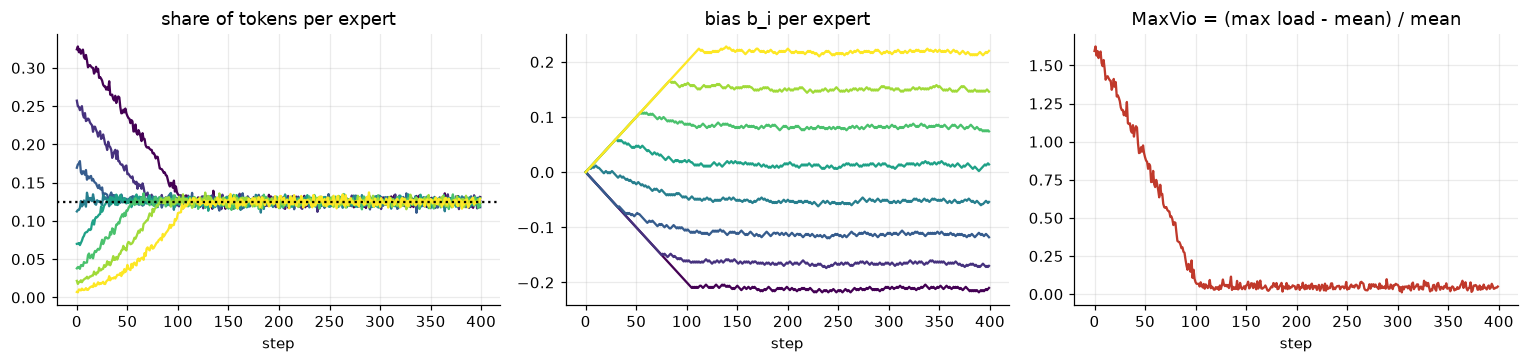

PASS - without bias the favoured expert is heavily overloaded (MaxVio 1.59)
PASS - the loop brings MaxVio under 0.1 (0.050)
PASS - favoured experts end with negative bias, unfavoured with positive 


In [3]:
torch.manual_seed(0)
E, N_TOK, K_SEL = 8, 4000, 2
means = torch.linspace(1.0, -1.0, E)                         # expert 0 scores highest on average, expert 7 lowest
def affinities(n):
    return torch.sigmoid(means + 0.8 * torch.randn(n, E))   # sigmoid scores, like the paper

def loads_with_bias(bias):
    idx = (affinities(N_TOK) + bias).topk(K_SEL, dim=-1).indices
    return torch.bincount(idx.reshape(-1), minlength=E).float()

maxvio = lambda load: float((load.max() - load.mean()) / load.mean())

bias = torch.zeros(E)
gamma = 0.002
trace = []
for step in range(400):
    load = loads_with_bias(bias)
    trace.append((maxvio(load), bias.clone(), load / load.sum()))
    bias += gamma * torch.sign(load.mean() - load)          # exactly update_bias, on a bare tensor

print("step    0: loads", [round(float(v), 3) for v in trace[0][2]], f" MaxVio {trace[0][0]:.2f}")
print("step  399: loads", [round(float(v), 3) for v in trace[-1][2]], f" MaxVio {trace[-1][0]:.2f}")
print("final bias:      ", [round(float(v), 3) for v in trace[-1][1]])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
shares = torch.stack([t[2] for t in trace]); biases = torch.stack([t[1] for t in trace])
for i in range(E):
    ax[0].plot(shares[:, i], color=plt.cm.viridis(i / (E - 1)))
    ax[1].plot(biases[:, i], color=plt.cm.viridis(i / (E - 1)))
ax[0].axhline(1 / E, color="k", ls=":"); ax[0].set(title="share of tokens per expert", xlabel="step")
ax[1].set(title="bias b_i per expert", xlabel="step")
ax[2].plot([t[0] for t in trace], color=C["red"]); ax[2].set(title="MaxVio = (max load - mean) / mean", xlabel="step")
plt.tight_layout(); plt.show()
check("without bias the favoured expert is heavily overloaded", trace[0][0] > 0.8, "(MaxVio %.2f)" % trace[0][0])
check("the loop brings MaxVio under 0.1", trace[-1][0] < 0.1, "(%.3f)" % trace[-1][0])
check("favoured experts end with negative bias, unfavoured with positive", float(trace[-1][1][0]) < 0 < float(trace[-1][1][-1]))

Three observations. The experts' shares converge to $1/8$. The biases settle at a spread that exactly offsets the difference in the router's preference. And the loads keep a small jitter, because $\gamma$ is a fixed step size: a larger $\gamma$ converges faster but jitters more, a smaller one is smoother but slower. DeepSeek-V3 uses $\gamma = 0.001$ for most of training and sets it to $0$ for the last 500B tokens (paper, section 4.2), after which the biases are frozen.

An important property: this is **not a gradient**. The bias is not a parameter that the optimiser sees, it is a buffer. The language-modelling loss never has to trade against balance, because balance is enforced in the choice, not in the objective.

## 3. The detail that matters: the bias only chooses, it never weights

The bias changes *which* experts are picked. The gate value that multiplies an expert's output must still come from the **original** affinity $s_{i,t}$ (paper: "the bias term is only used for routing"). If the bias leaked into the gate, a token forced onto an unattractive expert by a big positive bias would give that expert a large weight, and the output would be distorted by the balancing machinery itself.

Check it on the kit's layer, with a bias that forces an unattractive expert into the top-2:

In [4]:
torch.manual_seed(0)
layer = K.DeepSeekMoE(d=16, d_ff=8, n_shared=0, n_routed=6, top_k=2)
u = torch.randn(1, 16)
aff, idx0, g0 = layer.route(u)
worst = int(aff[0].argmin())                                  # the expert this token likes LEAST
layer.bias[worst] = 5.0                                       # a huge bias forces it into the selection
aff1, idx1, g1 = layer.route(u)

naive_scores = aff1 + layer.bias                              # what a leaky implementation would use for the gate
naive_g = naive_scores.gather(1, idx1); naive_g = naive_g / naive_g.sum(-1, keepdim=True)

print("token's affinities           :", [round(float(v), 2) for v in aff[0]], " least-liked expert:", worst)
print("selected without bias        :", idx0[0].tolist(), " gates", [round(float(v), 2) for v in g0[0]])
print("selected with bias on expert %d:" % worst, idx1[0].tolist(), " gates", [round(float(v), 2) for v in g1[0]])
print("gates if the bias leaked in  :", [round(float(v), 2) for v in naive_g[0]], " <- the forced expert would dominate")
forced_pos = idx1[0].tolist().index(worst)
check("the biased expert is now selected", worst in idx1[0].tolist() and worst not in idx0[0].tolist())
check("its gate stays small, computed from the original affinity", float(g1[0, forced_pos]) < 0.5)
check("the affinities themselves are untouched by the bias", torch.equal(aff, aff1))
check("a leaky gate would give the forced expert a much larger weight", float(naive_g[0, forced_pos]) > float(g1[0, forced_pos]) + 0.15)

token's affinities           : [0.58, 0.37, 0.17, 0.51, 0.08, 0.51]  least-liked expert: 4
selected without bias        : [0, 3]  gates [0.53, 0.47]
selected with bias on expert 4: [4, 0]  gates [0.12, 0.88]
gates if the bias leaked in  : [0.9, 0.1]  <- the forced expert would dominate
PASS - the biased expert is now selected 
PASS - its gate stays small, computed from the original affinity 
PASS - the affinities themselves are untouched by the bias 
PASS - a leaky gate would give the forced expert a much larger weight 


/var/folders/_q/55b37d8s6sq3xq4j5ll92c400000gn/T/ipykernel_45772/1598580096.py:12: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  print("token's affinities           :", [round(float(v), 2) for v in aff[0]], " least-liked expert:", worst)


## 4. A skewed problem: balance versus accuracy

Now training. We need a problem where balance and accuracy genuinely pull against each other. Same construction as notebook 2: inputs carry a domain label, and the target depends on the domain, $\mathbf y = B_z \mathbf x$. This time the domains are **unevenly frequent** (probability $\propto 1/(z+1)^{1.2}$, so domain 0 is about 43% of all tokens). A router that sends each domain to "its" experts will overload the experts of domain 0. A perfectly balanced router has to spread domain 0 over several experts, which each then must also serve another domain.

Eight routed experts, two chosen per token. We compare three ways of running it:

- **none**: no balancing;
- **loss**: the classic auxiliary loss, over the whole batch, for several values of $\alpha$;
- **bias**: DeepSeek-V3's mechanism, for several values of $\gamma$.

We record the balance (MaxVio over the last 200 steps) and the held-out error. Because the bias acts on *choices* and the loss acts on *gradients*, we expect to see a different trade-off curve.

In [5]:
N_DOM, D_X, N_EXP, TOPK = 8, 16, 8, 2
zipf = torch.tensor([1 / (z + 1) ** 1.2 for z in range(N_DOM)]); zipf = zipf / zipf.sum()
print("domain frequencies:", [round(float(p), 2) for p in zipf])

def make_problem(seed=100):
    g = torch.Generator().manual_seed(seed)
    B = torch.randn(N_DOM, D_X, D_X, generator=g) / D_X ** .5
    def batch(n, gen):
        z = torch.multinomial(zipf, n, replacement=True, generator=gen)
        x = torch.randn(n, D_X, generator=gen)
        y = torch.einsum("nij,nj->ni", B[z], x)
        return torch.cat([x, F.one_hot(z, N_DOM).float()], -1), y, z
    return batch

class Toy(nn.Module):
    def __init__(self):
        super().__init__()
        self.moe = K.DeepSeekMoE(D_X + N_DOM, 32, 0, N_EXP, TOPK)
        self.out = nn.Linear(D_X + N_DOM, D_X)
    def forward(self, x):
        return self.out(x + self.moe(x.unsqueeze(1)).squeeze(1))

def mutual_information(z, e, n_dom=N_DOM, n_exp=N_EXP):
    """I(domain; expert) in bits, from the empirical joint distribution of (domain, chosen expert)."""
    joint = torch.zeros(n_dom, n_exp)
    for k in range(e.shape[1]):
        joint.index_put_((z, e[:, k]), torch.ones(len(z)), accumulate=True)
    joint = joint / joint.sum()
    pz, pe = joint.sum(1, keepdim=True), joint.sum(0, keepdim=True)
    nz = joint > 0
    return float((joint[nz] * torch.log2(joint[nz] / (pz @ pe)[nz])).sum())

def fit(method, hp, seed, steps=800, bs=256):
    torch.manual_seed(seed)
    batch = make_problem()
    gen = torch.Generator().manual_seed(seed)
    net = Toy()
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    vio = []
    for _ in range(steps):
        x, y, _ = batch(bs, gen)
        loss = F.mse_loss(net(x), y)
        load = net.moe.last["load"].float()
        vio.append(maxvio(load))
        if method == "loss":                                                 # the classic loss, over the whole batch
            loss = loss + K.seq_balance_loss(net.moe, 1, bs, hp)
        opt.zero_grad(); loss.backward(); opt.step()
        if method == "bias":
            K.update_bias(net.moe, hp)
    xv, yv, zv = batch(8192, torch.Generator().manual_seed(999))
    with torch.no_grad():
        mse = float(F.mse_loss(net(xv), yv))
    mi = mutual_information(zv, net.moe.last["idx"])
    return dict(mse=mse, maxvio=float(np.mean(vio[-200:])), mi=mi, vio=vio)

settings = [("none", 0.0)] + [("bias", g) for g in (0.001, 0.003, 0.01, 0.03)] + [("loss", a) for a in (0.001, 0.01, 0.1, 1.0)]
t0 = time.time()
runs = {}
for m, hp in settings:
    runs[(m, hp)] = [fit(m, hp, s) for s in range(2)]
    r = runs[(m, hp)]
    print(f"{m:5s} hp={hp:<6g} MaxVio {np.mean([x['maxvio'] for x in r]):5.2f}   val MSE {np.mean([x['mse'] for x in r]):.4f} +- {np.std([x['mse'] for x in r]):.4f}   I(domain;expert) {np.mean([x['mi'] for x in r]):.2f} bits")
print("time %.0f s" % (time.time() - t0))

domain frequencies: [0.43, 0.19, 0.11, 0.08, 0.06, 0.05, 0.04, 0.04]


none  hp=0      MaxVio  0.81   val MSE 0.0041 +- 0.0002   I(domain;expert) 1.64 bits


bias  hp=0.001  MaxVio  0.19   val MSE 0.0057 +- 0.0006   I(domain;expert) 1.43 bits


bias  hp=0.003  MaxVio  0.24   val MSE 0.0053 +- 0.0008   I(domain;expert) 1.42 bits


bias  hp=0.01   MaxVio  0.43   val MSE 0.0052 +- 0.0007   I(domain;expert) 1.51 bits


bias  hp=0.03   MaxVio  0.65   val MSE 0.0067 +- 0.0012   I(domain;expert) 1.46 bits


loss  hp=0.001  MaxVio  0.76   val MSE 0.0042 +- 0.0007   I(domain;expert) 1.55 bits


loss  hp=0.01   MaxVio  0.72   val MSE 0.0049 +- 0.0013   I(domain;expert) 1.47 bits


loss  hp=0.1    MaxVio  0.30   val MSE 0.0072 +- 0.0022   I(domain;expert) 1.30 bits


loss  hp=1      MaxVio  0.19   val MSE 0.0098 +- 0.0008   I(domain;expert) 1.15 bits
time 31 s


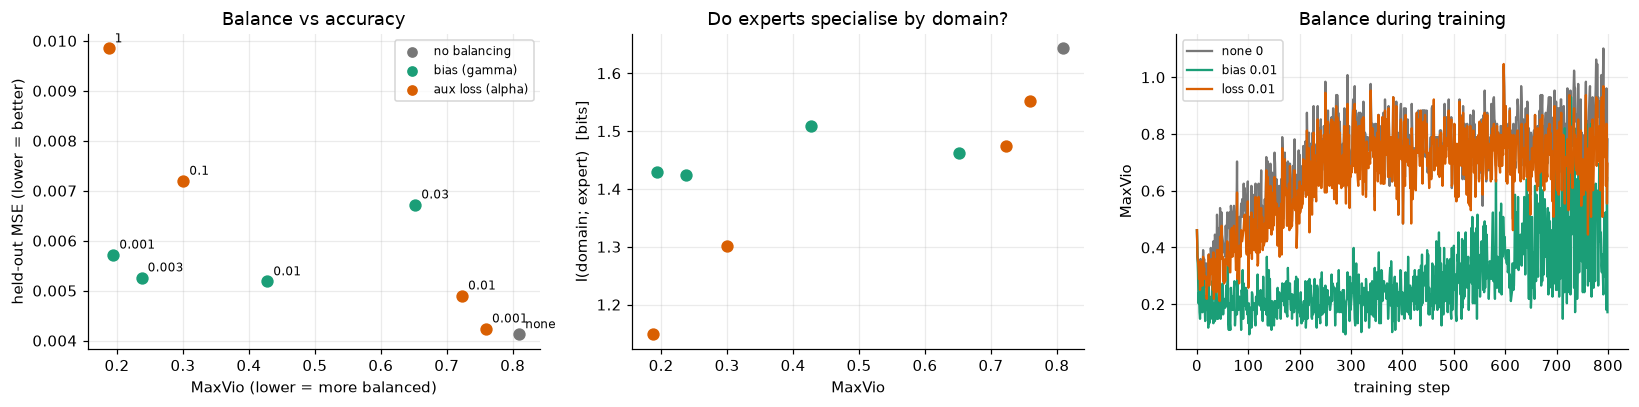

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
colors = {"none": C["grey"], "bias": C["green"], "loss": C["orange"]}
for (m, hp), r in runs.items():
    mv, ms, mi = np.mean([x["maxvio"] for x in r]), np.mean([x["mse"] for x in r]), np.mean([x["mi"] for x in r])
    ax[0].scatter(mv, ms, color=colors[m], s=50, zorder=3); ax[0].annotate(f"{hp:g}" if m != "none" else "none", (mv, ms), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax[1].scatter(mv, mi, color=colors[m], s=50, zorder=3)
for m in colors:
    ax[0].scatter([], [], color=colors[m], label={"none": "no balancing", "bias": "bias (gamma)", "loss": "aux loss (alpha)"}[m])
ax[0].set(xlabel="MaxVio (lower = more balanced)", ylabel="held-out MSE (lower = better)", title="Balance vs accuracy"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="MaxVio", ylabel="I(domain; expert)  [bits]", title="Do experts specialise by domain?")
for m, hp in [("none", 0.0), ("bias", 0.01), ("loss", 0.01)]:
    ax[2].plot(np.mean([x["vio"] for x in runs[(m, hp)]], 0), color=colors[m], label=f"{m} {hp:g}")
ax[2].set(xlabel="training step", ylabel="MaxVio", title="Balance during training"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [7]:
none = runs[("none", 0.0)]
best_b = min([k for k in runs if k[0] == "bias"], key=lambda k: np.mean([x["mse"] for x in runs[k]]) if np.mean([x["maxvio"] for x in runs[k]]) < 0.5 * np.mean([x["maxvio"] for x in none]) else 9)
best_l = min([k for k in runs if k[0] == "loss"], key=lambda k: np.mean([x["mse"] for x in runs[k]]) if np.mean([x["maxvio"] for x in runs[k]]) < 0.5 * np.mean([x["maxvio"] for x in none]) else 9)
f = lambda k, f_: np.mean([x[f_] for x in runs[k]])
print("MaxVio without balancing:", round(f(("none", 0.0), "maxvio"), 2), "  MSE", round(f(("none", 0.0), "mse"), 4))
print(f"best bias setting that halves MaxVio : gamma={best_b[1]:g}  MaxVio {f(best_b, 'maxvio'):.2f}  MSE {f(best_b, 'mse'):.4f}")
print(f"best loss setting that halves MaxVio : alpha={best_l[1]:g}  MaxVio {f(best_l, 'maxvio'):.2f}  MSE {f(best_l, 'mse'):.4f}")
check("the problem is imbalanced without balancing", f(("none", 0.0), "maxvio") > 0.5)
check("a bias setting halves the imbalance", f(best_b, "maxvio") < 0.5 * f(("none", 0.0), "maxvio"))
check("gamma too large overshoots: gamma=0.03 balances worse than gamma=0.003 (fixed step vs noisy batch loads)", f(("bias", 0.03), "maxvio") > f(("bias", 0.003), "maxvio"))
check("at similar balance (MaxVio < 0.3) the bias gives a lower error than the loss", f(("bias", 0.001), "mse") < f(("loss", 1.0), "mse") and f(("bias", 0.001), "maxvio") < 0.3 and f(("loss", 1.0), "maxvio") < 0.3, "(%.4f vs %.4f)" % (f(("bias", 0.001), "mse"), f(("loss", 1.0), "mse")))
check("a larger alpha gives better balance than a tiny alpha", f(("loss", 1.0), "maxvio") < f(("loss", 0.001), "maxvio"))

MaxVio without balancing: 0.81   MSE 0.0041
best bias setting that halves MaxVio : gamma=0.003  MaxVio 0.24  MSE 0.0053
best loss setting that halves MaxVio : alpha=0.1  MaxVio 0.30  MSE 0.0072
PASS - the problem is imbalanced without balancing 
PASS - a bias setting halves the imbalance 
PASS - gamma too large overshoots: gamma=0.03 balances worse than gamma=0.003 (fixed step vs noisy batch loads) 
PASS - at similar balance (MaxVio < 0.3) the bias gives a lower error than the loss (0.0057 vs 0.0098)
PASS - a larger alpha gives better balance than a tiny alpha 


How to read the left plot: down is better accuracy, left is better balance. The question is which method reaches a given balance at a lower error. Look at the printed table together with the seed spreads before concluding anything: the paper's finding (its Table 5) is that the bias method reaches balance with lower loss, at 2.4B to 20.9B active parameters over hundreds of billions of tokens. An 800-step toy can show whether the *mechanism* is sound (the bias reaches balance without a gradient) and what the trade looks like in a problem we constructed, but it is not a replication of that table.

What our run shows: without balancing, MaxVio is 0.81 and the error is lowest (0.0041), so **balance costs accuracy in every variant**, as it must on a problem where domain 0 really is 43% of the data. At a similar balance (MaxVio about 0.2) the bias method (gamma = 0.001) has an error of 0.0057 and the loss method (alpha = 1) 0.0098, so the bias is the cheaper way to get there here. Two caveats: a **gamma that is too large overshoots** (gamma = 0.03 is *less* balanced than 0.003, because the fixed step is large compared with the noisy loads of a 256-token batch), and the differences at moderate settings are within about one to two seed spreads (two seeds).

## 5. The complementary sequence-wise loss

V3 keeps a very small loss next to the bias ($\alpha = 0.0001$). The reason: the bias balances the load over a **whole batch**, but a single sequence can still be badly skewed, for example a long stretch of code that all goes to the same few experts. That does not hurt average training throughput but it can hurt a deployment that serves one sequence at a time. The sequence-wise loss (paper eqs. 17 to 20) penalises imbalance *within each sequence*:

$$ \mathcal L_{Bal} = \alpha \sum_{i=1}^{N_r} f_i P_i,\qquad f_i = \frac{N_r}{K_r T}\sum_{t=1}^{T}\mathbb 1\big[\,i \in \mathrm{Top}K_r\,\big],\qquad P_i=\frac1T\sum_{t=1}^T \frac{s_{i,t}}{\sum_j s_{j,t}} . $$

With perfect balance $f_i = 1$ and $P_i = 1/N_r$, so $\mathcal L_{Bal} = \alpha$. Imbalance makes it larger. The kit implements it as `seq_balance_loss`. Its value for balanced and for fully collapsed routing:

In [8]:
B_, T_, Nr_, Kr_ = 2, 64, 8, 2
moe_chk = K.DeepSeekMoE(8, 4, 0, Nr_, Kr_)
def loss_for(idx_rule, aff_rule):
    idx = idx_rule.view(B_ * T_, Kr_); aff = aff_rule
    moe_chk.last = dict(load=torch.bincount(idx.reshape(-1), minlength=Nr_), aff=aff, idx=idx)
    return float(K.seq_balance_loss(moe_chk, B_, T_, 1.0))

t_ids = torch.arange(B_ * T_)
balanced_idx = torch.stack([t_ids % Nr_, (t_ids + 1) % Nr_], 1)                    # round-robin
balanced_aff = torch.full((B_ * T_, Nr_), 0.5)
collapsed_idx = torch.zeros(B_ * T_, Kr_, dtype=torch.long); collapsed_idx[:, 1] = 1  # always experts 0 and 1
collapsed_aff = torch.full((B_ * T_, Nr_), 0.1); collapsed_aff[:, :2] = 0.9
l_bal, l_col = loss_for(balanced_idx, balanced_aff), loss_for(collapsed_idx, collapsed_aff)
print(f"loss / alpha when balanced: {l_bal:.3f}   when collapsed onto 2 of 8 experts: {l_col:.3f}")
check("balanced routing gives loss = alpha", abs(l_bal - 1.0) < 1e-5)
check("collapsed routing gives a larger loss", l_col > 2.5)

loss / alpha when balanced: 1.000   when collapsed onto 2 of 8 experts: 3.000
PASS - balanced routing gives loss = alpha 
PASS - collapsed routing gives a larger loss 


## 6. Specialisation

The paper makes a second claim for the bias method (section 4.5.3, Figure 9): because it only enforces balance over the whole batch and not per sequence or per domain, experts are free to specialise in a domain even if that domain is rare in a given sequence, while a loss-based method that pushes every sequence towards uniform use makes experts look alike.

![Paper Figure 9: expert load on three domains. The aux-loss-free model (rows 2 and 4) shows clearly uneven, domain-dependent loads; the aux-loss model is nearly uniform.](../../assets/deepseek_v3/fig9_expert_load.png)

*Figure 9 of the paper. Relative expert load on Wikipedia, GitHub and DM Mathematics text. The auxiliary-loss-free model (rows 2 and 4) has experts that are strongly preferred by one domain; the loss-based model's load is almost the same for all domains.*

We measured the same thing on our toy with the mutual information $I(\text{domain};\text{expert})$ between a token's domain and the expert it was sent to (right-hand plot above): zero would mean experts are used identically in every domain; higher means more specialised. The check:

In [9]:
mi = lambda k: np.mean([x["mi"] for x in runs[k]])
mv = lambda k: np.mean([x["maxvio"] for x in runs[k]])
print(f"I(domain;expert): none {mi(('none', 0.0)):.2f} | bias g=0.01 {mi(('bias', 0.01)):.2f} | loss a=0.01 {mi(('loss', 0.01)):.2f} | loss a=1.0 {mi(('loss', 1.0)):.2f}  bits  (max possible about {math.log2(N_DOM):.1f})")
print(f"MaxVio at those settings:               {mv(('none', 0.0)):.2f}   | {mv(('bias', 0.01)):.2f}  | {mv(('loss', 0.01)):.2f} | {mv(('loss', 1.0)):.2f}")
check("a very strong auxiliary loss reduces domain specialisation relative to no balancing", mi(("loss", 1.0)) < mi(("none", 0.0)))

I(domain;expert): none 1.64 | bias g=0.01 1.51 | loss a=0.01 1.47 | loss a=1.0 1.15  bits  (max possible about 3.0)
MaxVio at those settings:               0.81   | 0.43  | 0.72 | 0.19
PASS - a very strong auxiliary loss reduces domain specialisation relative to no balancing 


## 7. The same comparison in a small language model

The toy is useful because we constructed the trade-off. The question for the real model is whether the same mechanism holds in a language model. We train the notebook-2 language model (96 wide, 3 layers, 8 routed experts, 2 per token, one shared) in four ways. All use the same seeds and data; the training signal differs only in how balance is handled. Because this run is 200 steps instead of 14.8 trillion tokens, $\gamma$ has to be larger than the paper's 0.001 to move at all.

- **none**
- **bias**, $\gamma = 0.01$
- **batch loss**, $\alpha = 0.01$ (a Switch-style auxiliary loss over the whole batch)
- **bias + sequence loss**, $\gamma=0.01$, $\alpha_{seq}=0.01$ (V3's combination, with a stronger sequence loss than its 0.0001 so that it is visible at this scale)

We record the held-out language-modelling loss, MaxVio per batch, and MaxVio per *sequence* (averaged over sequences). The last number has a floor: even a perfectly uniform random router sends only $2\times 48 = 96$ expert slots per sequence to 8 experts, so some unevenness is unavoidable; we compute that floor.

In [10]:
data = K.CharData()
cfg = K.LMConfig(vocab=data.vocab, d=96, n_layers=3, n_heads=4, attn="mha", ffn="moe", n_shared=1, n_routed=8, top_k=2, moe_ff=64)
T_lm, B_lm = 48, 32

# floor: per-sequence MaxVio of a router that picks experts uniformly at random
g_ = torch.Generator().manual_seed(0)
fl = []
for _ in range(500):
    slots = torch.stack([torch.randperm(8, generator=g_)[:2] for _ in range(T_lm)]).reshape(-1)
    c = torch.bincount(slots, minlength=8).float(); fl.append(maxvio(c))
floor = float(np.mean(fl))
print(f"per-sequence MaxVio of a UNIFORM RANDOM router at T={T_lm}: {floor:.2f}")

@torch.no_grad()
def balance_stats(model):
    model.eval()
    batch = data.batch("val", 64, T_lm, torch.Generator().manual_seed(7))
    K.lm_loss(model, batch)
    pb, ps = [], []
    for m in model.moes():
        idx = m.last["idx"]                                              # (64*T, K)
        pb.append(maxvio(torch.bincount(idx.reshape(-1), minlength=8).float()))
        per_seq = idx.view(64, T_lm, 2).reshape(64, -1)
        ps.append(np.mean([maxvio(torch.bincount(r, minlength=8).float()) for r in per_seq]))
    model.train()
    return float(np.mean(pb)), float(np.mean(ps))

conds = {"none": dict(), "bias g=0.01": dict(gamma=0.01), "batch loss a=0.01": dict(batch_alpha=0.01),
         "bias + seq loss": dict(gamma=0.01, seq_alpha=0.01)}
res7 = {}
t0 = time.time()
for name, kw in conds.items():
    rows = []
    for seed in range(2):
        model, _ = K.train_lm(cfg, data, steps=200, B=B_lm, T=T_lm, lr=3e-3, seed=seed, **kw)
        loss = K.evaluate(model, data, T=T_lm, n_batches=10)["main"]
        pb, ps = balance_stats(model)
        rows.append((loss, pb, ps))
    res7[name] = np.array(rows)
    r = res7[name].mean(0)
    print(f"{name:20s} val loss {r[0]:.3f}   batch MaxVio {r[1]:.2f}   per-sequence MaxVio {r[2]:.2f}   (2 seeds, loss spread {res7[name][:,0].std():.3f})")
print("time %.0f s" % (time.time() - t0))

per-sequence MaxVio of a UNIFORM RANDOM router at T=48: 0.39


none                 val loss 2.862   batch MaxVio 1.40   per-sequence MaxVio 1.51   (2 seeds, loss spread 0.117)


bias g=0.01          val loss 2.781   batch MaxVio 0.25   per-sequence MaxVio 0.64   (2 seeds, loss spread 0.029)


batch loss a=0.01    val loss 2.797   batch MaxVio 0.25   per-sequence MaxVio 0.61   (2 seeds, loss spread 0.011)


bias + seq loss      val loss 2.795   batch MaxVio 0.12   per-sequence MaxVio 0.53   (2 seeds, loss spread 0.000)
time 44 s


In [11]:
r = {k: v.mean(0) for k, v in res7.items()}
check("per-sequence imbalance is higher than batch imbalance for every setting", all(v[2] > v[1] for v in r.values()))
check("per-sequence MaxVio has a floor well above 0 even for a uniform random router", floor > 0.3)
check("the bias lowers batch imbalance compared with no balancing", r["bias g=0.01"][1] < r["none"][1], "(%.2f vs %.2f)" % (r["bias g=0.01"][1], r["none"][1]))
spread = max(v[:, 0].std() for v in res7.values())
print(f"loss gap bias - none {r['bias g=0.01'][0] - r['none'][0]:+.3f}, batch-loss - none {r['batch loss a=0.01'][0] - r['none'][0]:+.3f}   (largest seed spread {spread:.3f})")

PASS - per-sequence imbalance is higher than batch imbalance for every setting 
PASS - per-sequence MaxVio has a floor well above 0 even for a uniform random router 
PASS - the bias lowers batch imbalance compared with no balancing (0.25 vs 1.40)
loss gap bias - none -0.081, batch-loss - none -0.066   (largest seed spread 0.117)


## What to take away

1. **Balance as a control loop, not a gradient.** A per-expert bias, added only to the *selection* score and nudged by a fixed $\gamma$ after every step, drives the load towards uniform. The optimiser never sees it, so the language-modelling loss does not have to trade against balance.
2. **The gate values must come from the unbiased affinity.** We verified that a leaky implementation would distort the output.
3. **There is still a small sequence-wise loss.** Batch-level balance leaves single sequences uneven; the loss ($\alpha=0.0001$ in V3) protects against extreme cases. Even uniform random routing is uneven per sequence, so some per-sequence imbalance is a floor, not a defect.
4. **Balance and specialisation pull against each other**, in our toy and in the paper's Figure 9: forcing uniform use everywhere makes experts alike.

## What this notebook does not show
- **The paper's quality result (its Table 5).** That claim comes from 15.7B and 228.7B-parameter models trained on 1.3T and 578B tokens. Our toy shows the mechanism and the shape of the trade-off at tiny scale; the language-model runs (2 seeds, 200 steps) are too short and too few for the loss differences to be anything but noise unless they exceed the printed spread.
- **Multi-node effects.** The expert load that matters in production is per GPU after expert parallelism, not per expert on one machine.
- **$\gamma=0.001$.** We used larger values because our runs are about 10 orders of magnitude shorter than V3's.

*Next:* notebook 4 covers multi-token prediction.

In [12]:
print("passed:", len(PASS), "| failed:", len(FAIL))
assert not FAIL, FAIL

passed: 18 | failed: 0
